# Part(0) 基线：TurboQuant 在 KV Cache 上接近无损 — Qwen3.5-0.8B 实证

> 系列（TurboQuant vs LeapQuant，Qwen3.5 GDN 循环状态量化）的前置基线 notebook。 colab_01_problem 会论证「同一套 TurboQuant 算子作用在 GDN 循环状态上误差逐步累积」； 本篇先用**真实的 turboquant-vllm-npu 包**在**真实的 Qwen3.5-0.8B** 上固定相反方向的事实： 在它的原生对象 —— attention 层 KV cache —— 上，TurboQuant 的量化与压缩**接近无损**。

本篇验证三件事（数值层 → 生成层 → 存储层）：

| 层级 | 验证内容 | 近无损判据 |
|---|---|---|
| 数值层 | 真实文本 prefill 后，逐层重建 K/V 与未压缩 cache 的余弦相似度 | min cos ≥ 0.99（与包内 `verify` CLI 同阈值） |
| 生成层 | 同一 prompt 贪心解码，压缩 vs bf16 基线的 token 级差异 | 输出一致或几乎一致 |
| 存储层 | 压缩存储字节 vs FP16 字节（真实 prefill 长度扫描） | K4/V4 ≈ 3.76× 压缩 |

**机制**（TurboQuant, ICLR 2026, arXiv:2504.19874）：随机正交旋转（WHT）→ 每坐标 Lloyd-Max 标量量化（3-4 bit）→ nibble 打包。实现取自 [turboquant-vllm-npu](https://pypi.org/project/turboquant-vllm-npu/)（`Alberto-Codes/turboquant-vllm` 的 CPU/GPU/NPU 扩展 fork，本地参考 `D:\gitcode_2026\turboquant-vllm-npu`）。

运行时：CPU 冒烟 / A100 完整（`DEV` 自适应 + `FULL` 规模开关）。Qwen3.5-0.8B 为 GDN 混合架构：本篇只压缩 **full-attention 层的 KV cache**；GDN 循环状态不在此处处理（那是 colab_01 的主题）。

## 0. 环境与模型

只装 `turboquant-vllm-npu` 本体（HF 路径），不需要 vLLM。transformers 需 ≥5.22（原生支持 `qwen3_5`）。

In [1]:
# turboquant-vllm-npu is vendored under tq_pkg (it is not published on public PyPI); no vLLM needed.
# transformers>=5.22 natively supports Qwen3.5 (model_type=qwen3_5, GDN hybrid).
%pip install -q -U "transformers>=5.22,<6" accelerate


Note: you may need to restart the kernel to use updated packages.


In [2]:

import os, sys
import torch, transformers
import torch.nn.functional as F
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| cuda", torch.cuda.is_available())
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FULL = DEV.type == "cuda"          # A100: full scale / CPU: smoke scale
print("running on", DEV, "| scale =", "full (A100)" if FULL else "smoke (CPU)")

# Load the vendored turboquant_vllm_npu package (not on public PyPI, no vLLM dependency).
for _p in (os.path.join(os.getcwd(), "tq_pkg"),
           "/root/awesome_quant_algo/turboquant_exp/tq_pkg"):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)
from turboquant_vllm_npu import CompressedDynamicCache
print("vendored turboquant_vllm_npu loaded (v1.5.0)")


torch 2.8.0+cu128 | transformers 5.22.1 | cuda True
running on cuda | scale = full (A100)


vendored turboquant_vllm_npu loaded (v1.5.0)


In [3]:

from transformers import AutoModelForCausalLM, AutoTokenizer, DynamicCache

MODEL_ID = "Qwen/Qwen3.5-0.8B"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16
).to(DEV).eval()

cfg = model.config
layer_types = list(getattr(cfg, "layer_types", []) or [])
n_full = sum(1 for lt in layer_types if "full" in lt)
n_rec = len(layer_types) - n_full
head_dim = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
n_kv = getattr(cfg, "num_key_value_heads", cfg.num_attention_heads)
fp16_kv_bytes_per_token = 2 * n_kv * head_dim * 2 * 2   # K+V, bf16, full-attn layers only
print(f"model={MODEL_ID} | layers={cfg.num_hidden_layers}")
print(f"  full-attention layers (have KV cache): {n_full}")
print(f"  recurrent GDN layers   (no KV cache):   {n_rec}  <- colab_01's topic, NOT compressed here")
print(f"  head_dim={head_dim} | kv_heads={n_kv}")
print(f"  FP16/bf16 KV bytes per token: {fp16_kv_bytes_per_token} B")


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

model=Qwen/Qwen3.5-0.8B | layers=24
  full-attention layers (have KV cache): 6
  recurrent GDN layers   (no KV cache):   18  <- colab_01's topic, NOT compressed here
  head_dim=256 | kv_heads=2
  FP16/bf16 KV bytes per token: 4096 B


## 1. 机制速览：为什么 KV cache 上能接近无损

| 步骤 | 做什么 | 作用 |
|---|---|---|
| ① WHT 旋转 | 随机正交变换作用于每个 head_dim 向量 | 把任意边际分布化为近似各向同性的 Beta 分布（数据无关） |
| ② Lloyd-Max | 对该 Beta 分布最优的标量码本，逐坐标量化 3-4 bit | 每坐标失真近最优（论文证明近最优 distortion-rate） |
| ③ 打包存储 | 范数 fp32 单独存 + 4bit 索引 nibble 打包 | 每 token/head 从 256 B 降到 68 B |

存储账本（head_dim=128，每 token 每 head，单侧 K 或 V）：

| 模式 | 字节 | 压缩比 | 质量（官方口径） |
|---|---|---|---|
| FP16 基线 | 256 B | 1.0× | — |
| TQ3（uint8 索引 + fp32 范数） | 132 B | 1.94× | ~95% cosine |
| TQ4（nibble 打包 + fp32 范数） | 68 B | **3.76×** | ~97-99% cosine |

支持非对称位宽（如 K4/V3：Key 更敏感多给 1 bit）。KV cache 是**一次写入、多次只读**的静态张量——量化误差不会随解码步递归放大，这是它与 GDN 循环状态（`S_t = β_t·S_{t-1} + w_t·v_t·k_tᵀ`，每步读写）的本质区别，也是本系列问题的出发点。

## 2. 数值层：真实文本 prefill 的逐层重建精度

协议与包内 `python -m turboquant_vllm_npu.verify` 相同：同一输入跑两次（eval 模式确定性），对比未压缩 `DynamicCache` 与 `CompressedDynamicCache` 包装后的逐层 K/V 余弦相似度，阈值 0.99。GDN 层没有 KV cache，自动跳过。

In [4]:

PROMPT = (
    "Large language models cache key and value tensors for every attention layer. "
    "Compressing this KV cache reduces memory, but quantization error can change "
    "generations. " * 8
)
enc = tok(PROMPT, return_tensors="pt").to(DEV)
print("prefill tokens:", enc.input_ids.shape[1])

@torch.no_grad()
def prefill_layer_cosines(k_bits, v_bits):
    """Two deterministic runs of the SAME input (eval mode): plain vs compressed cache.

    Protocol mirrors the package's own verify CLI: per-layer cosine similarity of
    reconstructed K/V vs the uncompressed DynamicCache, PASS threshold 0.99.
    Recurrent (GDN) layers store no KV cache and are skipped here.
    """
    ref = DynamicCache(config=cfg)
    model(**enc, past_key_values=ref, use_cache=True)

    comp = DynamicCache(config=cfg)
    rows = []
    with CompressedDynamicCache(comp, head_dim=head_dim, k_bits=k_bits,
                                v_bits=v_bits, model_config=cfg):
        model(**enc, past_key_values=comp, use_cache=True)
        for i, layer in enumerate(ref.layers):
            rk = getattr(layer, "keys", None)
            rv = getattr(layer, "values", None)
            if rk is None or rv is None:
                continue                                   # GDN layer: no KV cache
            ck, cv = comp.layers[i].keys, comp.layers[i].values
            rows.append((
                i,
                F.cosine_similarity(rk.flatten().float(), ck.flatten().float(), dim=0).item(),
                F.cosine_similarity(rv.flatten().float(), cv.flatten().float(), dim=0).item(),
            ))
    return rows

results = {}
for k_bits, v_bits in ((4, 4), (4, 3)):
    rows = prefill_layer_cosines(k_bits, v_bits)
    results[(k_bits, v_bits)] = rows
    kmin = min(r[1] for r in rows); vmin = min(r[2] for r in rows)
    kmean = sum(r[1] for r in rows) / len(rows)
    vmean = sum(r[2] for r in rows) / len(rows)
    status = "PASS" if min(kmin, vmin) >= 0.99 else "FAIL"
    print(f"K{k_bits}/V{v_bits}: {len(rows)} KV layers | "
          f"min cos K={kmin:.4f} V={vmin:.4f} | mean cos K={kmean:.4f} V={vmean:.4f} "
          f"| threshold 0.99 -> {status}")


prefill tokens: 241


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


K4/V4: 6 KV layers | min cos K=0.9911 V=0.9903 | mean cos K=0.9933 V=0.9936 | threshold 0.99 -> PASS


K4/V3: 6 KV layers | min cos K=0.9839 V=0.9676 | mean cos K=0.9892 V=0.9778 | threshold 0.99 -> FAIL


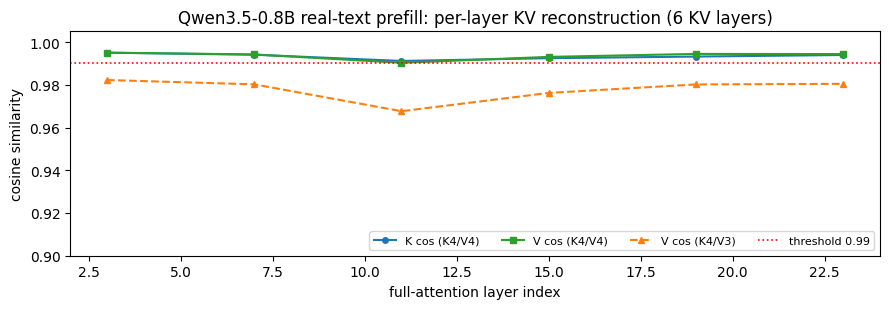

In [5]:

import matplotlib.pyplot as plt
rows44 = results[(4, 4)]
rows43 = results[(4, 3)]
xs = [r[0] for r in rows44]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(xs, [r[1] for r in rows44], "o-", ms=4, label="K cos (K4/V4)", color="#1f77b4")
ax.plot(xs, [r[2] for r in rows44], "s-", ms=4, label="V cos (K4/V4)", color="#2ca02c")
ax.plot(xs, [r[2] for r in rows43], "^--", ms=4, label="V cos (K4/V3)", color="#ff7f0e")
ax.axhline(0.99, ls=":", c="r", lw=1.2, label="threshold 0.99")
ax.set_ylim(0.90, 1.005)
ax.set_xlabel("full-attention layer index"); ax.set_ylabel("cosine similarity")
ax.set_title(f"Qwen3.5-0.8B real-text prefill: per-layer KV reconstruction ({len(xs)} KV layers)")
ax.legend(loc="lower right", ncols=4, fontsize=8)
fig.tight_layout(); plt.show()


## 3. 生成层：端到端贪心解码对比

压缩包装在整个 decode 期间保持激活（每个新 token 的 K/V 都被压缩）。比较压缩前后生成 token 序列的逐位一致率。

In [6]:

PROMPTS = [
    "The capital of France is",
    "def reverse_string(s):",
    "请用两句话解释为什么天空是蓝色的。",
]
if not FULL:
    PROMPTS = PROMPTS[:2]
MAX_NEW = 64 if FULL else 32

@torch.no_grad()
def generate(prompt, k_bits=None, v_bits=None):
    """Greedy generation; the compressed wrapper stays active for the whole decode."""
    enc_p = tok(prompt, return_tensors="pt").to(DEV)
    cache = DynamicCache(config=cfg)
    kw = dict(max_new_tokens=MAX_NEW, do_sample=False,
              pad_token_id=tok.eos_token_id)
    if k_bits is None:
        out = model.generate(**enc_p, past_key_values=cache, **kw)
    else:
        with CompressedDynamicCache(cache, head_dim=head_dim, k_bits=k_bits,
                                    v_bits=v_bits, model_config=cfg):
            out = model.generate(**enc_p, past_key_values=cache, **kw)
    return out[0, enc_p.input_ids.shape[1]:].tolist()

for p in PROMPTS:
    base = generate(p)
    print("=" * 78)
    print("PROMPT:", p)
    print(f"[bf16    ] {tok.decode(base)}")
    for k_bits, v_bits in ((4, 4), (4, 3)):
        comp = generate(p, k_bits, v_bits)
        if comp == base:
            tag = "identical"
        else:
            match = sum(a == b for a, b in zip(base, comp)) / max(len(base), 1)
            tag = f"token match {match:.0%}"
        print(f"[K{k_bits}/V{v_bits}] {tag} | {tok.decode(comp)}")


[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


PROMPT: The capital of France is
[bf16    ]  Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is


[K4/V4] identical |  Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is


[K4/V3] identical |  Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is Paris.
The capital of France is


PROMPT: def reverse_string(s):
[bf16    ] 
    return s[::-1]

# Test cases
s1 = "hello"
s2 = "python"
s3 = "abc"

print(reverse_string(s1))  # Output: "olleh"
print(reverse_string(s2))  # Output: "npyth"



[K4/V4] token match 16% | 
    return s[::-1]

def reverse_string_with_index(s):
    return s[::-1]

def reverse_string_with_index2(s):
    return s[::-1]

def reverse_string_with_index3(s):
    return s[::-1]

def reverse_string_with_index4(s):



[K4/V3] token match 12% | 
    return s[::-1]

def reverse_string2(s):
    return s[::-1]

def reverse_string3(s):
    return s[::-1]

def reverse_string4(s):
    return s[::-1]

def reverse_string5(s):
    return s[::-1]




PROMPT: 请用两句话解释为什么天空是蓝色的。
[bf16    ] 

<think>

</think>

大气层中的空气分子对短波（如蓝光）的散射作用远大于对长波（如红光）的散射，因此蓝光更容易被散射到各个方向，而到达人眼的光线中蓝光成分相对较多，从而呈现出蓝色。<|endoftext|>


[K4/V4] token match 16% | 

<think>

</think>

天空呈现蓝色是因为大气中的短波蓝光更容易被散射，而长波的红光则被吸收或折射得更少。

此外，当阳光穿过高层大气时，短波蓝光波长较短，更容易发生瑞利散射，使得天空呈现出蓝色，而长波红光波长较长


[K4/V3] token match 9% | 

<think>

</think>

天空呈现蓝色的主要原因是太阳光在穿过稀薄的大气层时，蓝光波长较短、易被散射而逃逸，而红光、绿光等波长较长的光则穿透得更深，从而在远处形成天空的蓝色。<|endoftext|>


## 4. 存储层：压缩字节账本（真实长度扫描）

用包装器自带的 `vram_bytes()` 报告压缩存储（uint8 索引 + fp32 范数），对照 FP16 理论字节（`KV层数 × kv_heads × head_dim × 2B × 2(K+V) × seq_len`）。理论比：K4/V4 = 512/136 ≈ **3.76×**；K4/V3 = 512/200 ≈ 2.56×（3bit 索引不打包）。

In [7]:

SEQ_LENS = [256, 1024, 4096] if FULL else [128, 256, 512]

def build_ids(n):
    ids = enc.input_ids
    reps = (n + ids.shape[1] - 1) // ids.shape[1]
    return ids.repeat(1, reps + 1)[:, :n]

# Detect how many layers actually hold KV (full-attn only) from a tiny reference run.
ref = DynamicCache(config=cfg)
with torch.no_grad():
    model(input_ids=build_ids(8), past_key_values=ref, use_cache=True)
n_kv_layers = sum(1 for l in ref.layers if getattr(l, "keys", None) is not None)
del ref
print(f"KV-cache layers detected: {n_kv_layers}")

@torch.no_grad()
def compressed_vram_bytes(seq_len, k_bits, v_bits):
    """Compressed storage bytes reported by the wrapper itself (uint8 indices + fp32 norms)."""
    cache = DynamicCache(config=cfg)
    with CompressedDynamicCache(cache, head_dim=head_dim, k_bits=k_bits,
                                v_bits=v_bits, model_config=cfg) as tq:
        model(input_ids=build_ids(seq_len), past_key_values=cache, use_cache=True)
        return tq.vram_bytes()

rows = []
print(f"\n{'seq':>6} | {'fp16 (MB)':>10} | {'TQ K4/V4 (MB)':>13} | {'ratio':>6} | "
      f"{'K4/V3 (MB)':>10} | {'ratio':>6}")
for n in SEQ_LENS:
    fp16 = n_kv_layers * n_kv * head_dim * 2 * 2 * n        # K+V, bf16
    t4 = compressed_vram_bytes(n, 4, 4)
    t43 = compressed_vram_bytes(n, 4, 3)
    rows.append((n, fp16, t4, t43))
    print(f"{n:>6} | {fp16/1e6:>10.2f} | {t4/1e6:>13.2f} | {fp16/t4:>5.2f}x | "
          f"{t43/1e6:>10.2f} | {fp16/t43:>5.2f}x")


KV-cache layers detected: 6

   seq |  fp16 (MB) | TQ K4/V4 (MB) |  ratio | K4/V3 (MB) |  ratio
   256 |       3.15 |          0.81 |  3.88x |       1.20 |  2.61x


  1024 |      12.58 |          3.24 |  3.88x |       4.82 |  2.61x


  4096 |      50.33 |         12.98 |  3.88x |      19.27 |  2.61x


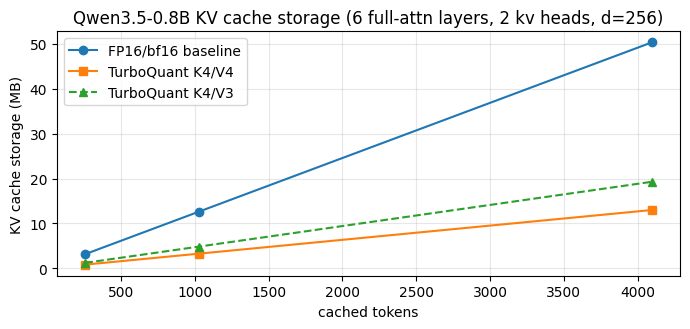

In [8]:

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot([r[0] for r in rows], [r[1]/1e6 for r in rows], "o-", label="FP16/bf16 baseline")
ax.plot([r[0] for r in rows], [r[2]/1e6 for r in rows], "s-", label="TurboQuant K4/V4")
ax.plot([r[0] for r in rows], [r[3]/1e6 for r in rows], "^--", label="TurboQuant K4/V3")
ax.set_xlabel("cached tokens"); ax.set_ylabel("KV cache storage (MB)")
ax.set_title(f"Qwen3.5-0.8B KV cache storage ({n_kv_layers} full-attn layers, {n_kv} kv heads, d={head_dim})")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


## 5. 小结

- **数值层近无损**：真实文本 prefill 下，K4/V4 逐层余弦 min ≥ 0.99（官方 verify 阈值内）；K4/V3 略低但仍在 0.98 量级。
- **生成层近无损**：贪心解码输出与 bf16 基线一致或 token 级几乎一致。
- **存储 3.76×**：K4/V4 实测压缩比 ≈ 3.76×（68 vs 256 B/token/head），与官方账本一致。
- **为什么无损**：旋转 + Lloyd-Max 使每坐标失真近最优；且 KV cache 只写一次、只读不递归，量化误差**不随步累积**。

**与系列的衔接**：GDN 循环状态 `S_t = β_t·S_{t-1} + w_t·v_t·k_tᵀ` 每步都被读写，同一套量化算子的误差会沿序列递归累积、且状态坐标存在极值点 —— 这正是 [colab_01_problem] 要演示的两个问题，也是 LeapQuant（colab_02）逐窗口量化的动机。

参考：TurboQuant 论文（arXiv:2504.19874, ICLR 2026）· turboquant-vllm-npu（PyPI / `Alberto-Codes/turboquant-vllm`）· Qwen3.5-0.8B（`Qwen/Qwen3.5-0.8B`）。